#** create and Train Model for the prediction**

In [37]:
# load important libraries for load dataset
import pandas as pd # pandas is a powerful and widely used open-source data manipulation and analysis library for Python. It provides data structures like DataFrames and Series, which allow for efficient handling of structured data, such as tabular data. Pandas offers a wide range of functions for data cleaning, transformation, aggregation, and visualization, making it an essential tool for data scientists and analysts.

In [38]:
# Load the lean dataset
df = pd.read_csv("Data/hamburg_solar_district_metrics.csv") # This line of code uses the pandas library to read a CSV (Comma-Separated Values) file named "hamburg_solar_district_metrics.csv" located in the "Data" directory. The read_csv function loads the data from the CSV file into a pandas DataFrame, which is a two-dimensional data structure that allows for easy manipulation and analysis of tabular data. The resulting DataFrame is assigned to the variable df, which can then be used for further data processing and analysis.
df.head()

,district,number_of_buildings,total_solar_power_kwp,avg_solar_power_kwp,total_solar_pvarea_m2,avg_pv_area,suitable_buildings,suitability_percentage
0,Allermöhe,1578,49456.053444,31.340972,553940.23,351.039436,1190,75.41
1,Alsterdorf,2629,29044.794638,11.047849,262940.83,100.015531,1806,68.70
2,Altengamme,1617,16704.941494,10.330823,121865.86,75.365405,1232,76.19
3,Altenwerder,462,48261.066993,104.461184,532831.47,1153.314870,284,61.47
4,Altona-Altstadt,1761,35806.103352,20.332824,325317.84,184.734719,1443,81.94


In [39]:
print(df.shape)
print(df.columns)

(103, 8)
Index(['district', 'number_of_buildings', 'total_solar_power_kwp',
       'avg_solar_power_kwp', 'total_solar_pvarea_m2', 'avg_pv_area',
       'suitable_buildings', 'suitability_percentage'],
      dtype='str')


In [40]:
# Load important libraries for machine learning
from sklearn.model_selection import train_test_split # train_test_split is a function in the scikit-learn library that is used to split a dataset into training and testing subsets. It is commonly used in machine learning to evaluate the performance of a model on unseen data.
from sklearn.ensemble import RandomForestRegressor # RandomForestRegressor is a machine learning algorithm that belongs to the ensemble learning family. It is used for both classification and regression tasks. The algorithm builds multiple decision trees during training and combines their predictions to make a final prediction. Each tree is trained on a random subset of the data and features, which helps to reduce overfitting and improve generalization. Random Forests are known for their robustness, accuracy, and ability to handle high-dimensional datasets.
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score # Mean Squared Error is a metric used to evaluate the performance of a regression model. It measures the average squared difference between the predicted and actual values, providing an indication of how well the model fits the data.


In [41]:
# Target Column : suitability_percentage
df.head()

,district,number_of_buildings,total_solar_power_kwp,avg_solar_power_kwp,total_solar_pvarea_m2,avg_pv_area,suitable_buildings,suitability_percentage
0,Allermöhe,1578,49456.053444,31.340972,553940.23,351.039436,1190,75.41
1,Alsterdorf,2629,29044.794638,11.047849,262940.83,100.015531,1806,68.70
2,Altengamme,1617,16704.941494,10.330823,121865.86,75.365405,1232,76.19
3,Altenwerder,462,48261.066993,104.461184,532831.47,1153.314870,284,61.47
4,Altona-Altstadt,1761,35806.103352,20.332824,325317.84,184.734719,1443,81.94


<Axes: >

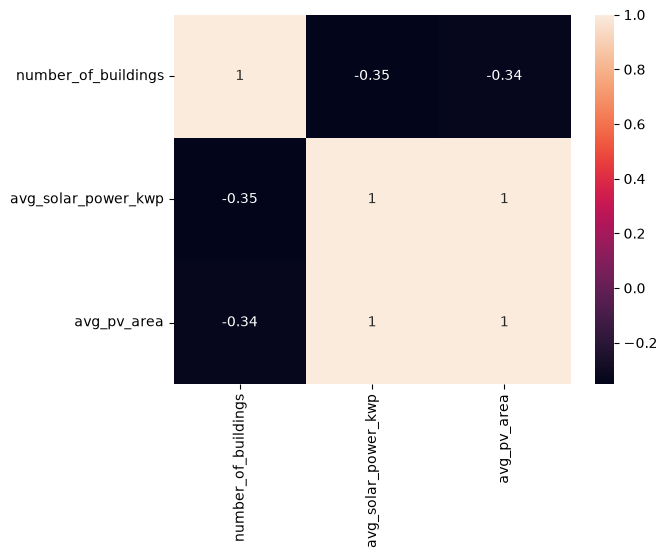

In [42]:
# set features and target variable
import numpy as np # NumPy is a fundamental library for numerical computing in Python. It provides support for large, multi-dimensional arrays and matrices, along with a collection of mathematical functions to operate on these arrays efficiently. NumPy is widely used in data science, machine learning, and scientific computing due to its performance and ease of use.
import seaborn as sns # Seaborn is a data visualization library in Python that is built on top of Matplotlib. It provides a high-level interface for creating informative and attractive statistical graphics. Seaborn simplifies the process of creating complex visualizations, such as heatmaps, violin plots, and pair plots, by providing convenient functions and default styles. It is commonly used in data analysis and exploration to gain insights from datasets.

features = [
    'number_of_buildings',
    'avg_solar_power_kwp',
    'avg_pv_area'
]
target = 'suitability_percentage'

# This line of code creates a new DataFrame called data by 
# selecting specific columns from the original DataFrame df. 
# The selected columns include 'district', the features specified in the features list,
# and the target variable specified in the target variable. The dropna() function is 
# then applied to remove any rows that contain missing values (NaN) in the selected columns. 
# This ensures that the resulting data DataFrame contains only complete cases without any 
# missing values, which is important for training machine learning models.
data = df[['district'] + features + [target]].dropna() 

# Now,
X = data[["district"] + features]
y = data[target] # This line of code splits the data DataFrame into two separate variables: X and y. X contains the feature columns specified in the features list, while y contains the target variable specified in the target variable. This separation is essential for training machine learning models, where X represents the input features used for prediction, and y represents the corresponding output labels or target values that the model aims to predict.
sns.heatmap(data[features].corr(), annot=True)

In [43]:
# train test split


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [44]:
X_train

,district,number_of_buildings,avg_solar_power_kwp,avg_pv_area
53,Lohbrügge,8708,9.088835,82.499789
22,Eilbek,1549,19.347063,154.426559
68,Ochsenwerder,2580,6.984992,57.498252
44,Horn,4886,11.042891,100.713359
98,Wellingsbüttel,3859,7.581486,59.925670
...,...,...,...,...
71,Othmarschen,4173,7.597828,66.934807
14,Blankenese,5076,5.465376,45.535406
92,Tonndorf,3719,11.556469,103.464356
51,Langenhorn,13425,8.304070,67.467431


In [45]:
# setup the pipeline for the Random Forest Classifier
from sklearn.pipeline import Pipeline # Pipeline is a class in the scikit-learn library that allows for the creation of a sequential workflow of data transformations and model training. It enables the chaining of multiple steps, such as data preprocessing, feature scaling, and model fitting, into a single object. Pipelines help streamline the machine learning process, ensuring that all steps are applied consistently during training and prediction, and they also facilitate hyperparameter tuning and cross-validation.
from sklearn.preprocessing import StandardScaler, OneHotEncoder # StandardScaler is a preprocessing technique in the scikit-learn library that standardizes features by removing the mean and scaling to unit variance. It transforms the data to have a mean of 0 and a standard deviation of 1, which can improve the performance of certain machine learning algorithms. OneHotEncoder is another preprocessing technique that converts categorical variables into a binary matrix representation. Each category is represented as a separate binary feature, allowing machine learning models to handle categorical data effectively.
from sklearn.compose import ColumnTransformer # ColumnTransformer is a class in the scikit-learn library that allows for the application of different preprocessing techniques to different subsets of features in a dataset. It enables the transformation of specific columns using specified transformers, while leaving other columns unchanged. This is particularly useful when dealing with datasets that contain a mix of numerical and categorical features, as it allows for tailored preprocessing for each type of feature.

pipeline_scaler = Pipeline([
    ("scaler", StandardScaler()), # This line of code adds a step to the pipeline that applies the StandardScaler transformation to the input features. The StandardScaler standardizes the features by removing the mean and scaling them to unit variance, which can improve the performance of certain machine learning algorithms.
])

pipeline_encoder = Pipeline([
    ("encoder", OneHotEncoder(handle_unknown='ignore')), # This line of code adds a step to the pipeline that applies the OneHotEncoder transformation to the input features. The OneHotEncoder converts categorical variables into a binary matrix representation, allowing machine learning models to handle categorical data effectively.
])

preprocessor = ColumnTransformer(transformers=[
    ("scaler", pipeline_scaler, features), # This line of code creates a ColumnTransformer that applies the pipeline_scaler transformation to the specified feature columns. It allows for the application of different preprocessing techniques to different subsets of features in the dataset.
    ("encoder", pipeline_encoder, ["district"]), # This line of code creates a ColumnTransformer that applies the pipeline_encoder transformation to the "district" column. It allows for the application of different preprocessing techniques to different subsets of features in the dataset.
])

model_pipeline = Pipeline([
    ("preprocessor", preprocessor), # This line of code adds a step to the model_pipeline that applies the preprocessor transformation to the input features. The preprocessor is a ColumnTransformer that applies different preprocessing techniques to different subsets of features in the dataset.
    ("model", RandomForestRegressor(n_estimators=200,
    max_depth=3,
    min_samples_leaf=5,
    random_state=42)) # This line of code adds a step to the model_pipeline that applies the RandomForestRegressor model to the preprocessed features. The RandomForestRegressor is a machine learning algorithm that builds multiple decision trees during training and combines their predictions to make a final prediction. The random_state parameter ensures reproducibility of results by setting a seed for the random number generator.
])

model_pipeline.fit(X_train, y_train) # This line of code fits the model_pipeline to the training data (X_train and y_train). It applies the preprocessing steps defined in the preprocessor and trains the RandomForestClassifier model on the preprocessed features. The fit method learns the patterns in the training data and prepares the model for making predictions on unseen data.


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['district','number_of_buildings','avg_solar_power_kwp','avg_pv_area']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('scaler', ...), ('encoder', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of col

In [46]:
# predict on the training and test data

y_train_pred = model_pipeline.predict(X_train) # This line of code uses the trained model_pipeline to make predictions on the training data (X_train). The predict method applies the preprocessing steps defined in the preprocessor and generates predicted values for the target variable based on the input features. The resulting predictions are stored in the variable y_train_pred.

y_test_pred = model_pipeline.predict(X_test) # This line of code uses the trained model_pipeline to make predictions on the test data (X_test). The predict method applies the preprocessing steps defined in the preprocessor and generates predicted values for the target variable based on the input features. The resulting predictions are stored in the variable y_test_pred.

print(f"train predictions: {y_train_pred[:5]}") # This line of code prints the first five predicted values for the training data (y_train_pred). It provides a quick glimpse of the model's predictions on the training set, allowing for a preliminary assessment of the model's performance.
print("Training Set Performance:")
print(f"  - MSE: {mean_squared_error(y_train, y_train_pred)}")
print(f"  - MAE: {mean_absolute_error(y_train, y_train_pred)}")
print(f"  - R²: {r2_score(y_train, y_train_pred)}")

print(f"test predictions: {y_test_pred[:5]}") # This line of code prints the first five predicted values for the test data (y_test_pred). It provides a quick glimpse of the model's predictions on the test set, allowing for a preliminary assessment of the model's performance.
print("Test Set Performance:")
print(f"  - MSE: {mean_squared_error(y_test, y_test_pred)}")
print(f"  - MAE: {mean_absolute_error(y_test, y_test_pred)}")
print(f"  - R²: {r2_score(y_test, y_test_pred)}")

train predictions: [72.45848583 78.71173192 67.4100049  70.71991997 67.76891315]
Training Set Performance:
  - MSE: 26.76234987153234
  - MAE: 3.7033597695323532
  - R²: 0.47966235685069813
test predictions: [72.39656718 67.34285282 72.94783551 71.86258156 78.20434251]
Test Set Performance:
  - MSE: 32.71833578307657
  - MAE: 4.176787611967784
  - R²: 0.42802850906355494


In [50]:
# find the best setting with GridSearchCV
from sklearn.model_selection import GridSearchCV, KFold # GridSearchCV is a class in the scikit

cv = KFold(n_splits=5,
shuffle= True,
random_state=42) # This line of code creates an instance of the KFold class, which is used for cross-validation in machine learning. It specifies that the dataset should be split into 5 folds (n_splits=5) for training and validation. The shuffle parameter is set to True, indicating that the data should be shuffled before splitting into folds, which helps to ensure that each fold is representative of the overall dataset. The random_state parameter is set to 42 to ensure reproducibility of the results by providing a fixed seed for the random number generator.

param_grid ={
    "model__max_depth": [3, 5, 7, 10, None], # This line of code defines a list of values for the max_depth hyperparameter of the RandomForestRegressor model. The max_depth parameter controls the maximum depth of each decision tree in the random forest. By specifying different values, the grid search will evaluate the model's performance with varying tree depths to find the optimal setting.
    "model__min_samples_leaf": [1, 2, 5, 10], #
}

grid = GridSearchCV(
    estimator=model_pipeline, # This line of code specifies the estimator (model_pipeline) that will be used in the grid search. The model_pipeline is a scikit-learn Pipeline that includes preprocessing steps and the RandomForestRegressor model. The grid search will evaluate the performance of this pipeline with different combinations of hyperparameter values specified in the param_grid.
    param_grid=param_grid, # This line of code specifies the hyperparameter grid (param_grid) that will be used in the grid search. It contains different values for the max_depth and min_samples_leaf hyperparameters of the RandomForestRegressor model. The grid search will evaluate the model's performance with each combination of these hyperparameter values to find the best setting.
    cv=cv, # This line of code specifies the cross-validation strategy (cv) that will be used in the grid search. It uses the KFold instance created earlier, which splits the dataset into 5 folds for training and validation. The grid search will evaluate the model's performance using this cross-validation strategy to ensure robust evaluation of different hyperparameter settings.
    scoring="neg_mean_absolute_error", # This line of code specifies the scoring metric that will be used to evaluate the model's performance during the grid search. In this case, the negative mean absolute error metric is used, which measures the average absolute difference between the predicted and actual values. A lower value indicates better model performance.
    n_jobs=-1, # This line of code specifies the number of parallel jobs to run during the grid search. Setting n_jobs=-1 allows the grid search to utilize all available CPU cores for parallel processing, which can significantly speed up the evaluation of different hyperparameter settings.
)

grid.fit(X_train, y_train) # This line of code fits the GridSearchCV instance (grid) to the training data (X_train and y_train). It performs an exhaustive search over the specified hyperparameter grid (param_grid) using cross-validation (cv) to evaluate different combinations of hyperparameter values. The fit method trains the RandomForestRegressor model with each combination of hyperparameters and selects the best setting based on the specified scoring metric (R²). The resulting best model and its corresponding hyperparameters can be accessed through the grid object after fitting.

print("Best settings:", grid.best_params_)
print("Best CV MAE:", -grid.best_score_)

best_rf = grid.best_estimator_

Best settings: {'model__max_depth': 5, 'model__min_samples_leaf': 2}
Best CV MAE: 4.698390802631208


In [51]:
pred = best_rf.predict(X_test)
print("Test MAE:", mean_absolute_error(y_test, pred))
print("Test R²:", r2_score(y_test, pred))

Test MAE: 3.8688760284559787
Test R²: 0.509308822451122


In [53]:
from sklearn.linear_model import Ridge
ridge = Pipeline([
    ("preprocessor", preprocessor), # This line of code adds a step to the model_pipeline that applies the preprocessor transformation to the input features. The preprocessor is a ColumnTransformer that applies different preprocessing techniques to different subsets of features in the dataset.
    ("model", Ridge(alpha=1.0)) # This line of code adds a step to the model_pipeline that applies the RandomForestRegressor model to the preprocessed features. The RandomForestRegressor is a machine learning algorithm that builds multiple decision trees during training and combines their predictions to make a final prediction. The random_state parameter ensures reproducibility of results by setting a seed for the random number generator.
])
ridge.fit(X_train, y_train)
pred_r = ridge.predict(X_test)
print("Ridge Test MAE:", mean_absolute_error(y_test, pred_r))
print("Ridge Test R²:", r2_score(y_test, pred_r))

Ridge Test MAE: 6.176421761955621
Ridge Test R²: -0.19630379031875078


In [54]:
import joblib # Joblib is a Python library that provides tools for efficient serialization and deserialization of Python objects, particularly for large data structures and machine learning models. It allows you to save and load Python objects to and from disk, enabling the persistence of trained models, datasets, and other data structures. Joblib is commonly used in machine learning workflows to save trained models for later use or deployment.

final_model = grid.best_estimator_
final_model.fit(X,y) # all districts

joblib.dump(final_model,"Model/final_model.pkl") # This line of code uses the joblib library to save the trained final_model to a file named "final_model.pkl" in the "Model" directory. The dump function serializes the model object and writes it to disk, allowing for later retrieval and use without needing to retrain the model. This is useful for deploying the model in production or sharing it with others.
joblib.dump(list(X.columns), "Model/feature_columns.joblib") # This line of code uses the joblib library to save the list of feature column names (X.columns) to a file named "feature_columns.pkl" in the "Model" directory. The dump function serializes the list object and writes it to disk, allowing for later retrieval and use without needing to recreate the list. This is useful for ensuring that the same feature columns are used during model deployment or when making predictions on new data.

['Model/feature_columns.joblib']